# Mini-Jev · v1: Supervised fine-tuning on Jev's top answer

**What this does:** teaches Qwen3-1.7B to pick the same option Jev picked, using QLoRA. Then grades it on the exact same 2,000-question exam as v0.

**Why:** v0 showed the base model mostly answers "B" no matter what, and puts ~27% of its probability on non-letter tokens. SFT should fix both. The open question is calibration: training only on "the answer is B" never shows the model that Jev was only 60% sure. **We expect v1 to agree with Jev far more, but stay overconfident.** v2 tests whether showing it Jev's full probabilities fixes that.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -U transformers accelerate peft bitsandbytes

name, memory.total [MiB]
Tesla T4, 15360 MiB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 72.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 50.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 16.9 MB/s eta 0:00:00


## Config
Knobs you might change: `N_TRAIN_USE` (set to `10_000` to halve training time) and `LR`. Leave the rest for now.

In [2]:
SEED = 42
MODEL_ID = "Qwen/Qwen3-1.7B"
SAVE_DIR = "/content/drive/MyDrive/mini-jev"
RUN_NAME = "v1"

N_TRAIN_USE = None     # None = all ~20k rows; 10_000 halves the time
N_VAL = 500            # carved from train, used to watch training. The 2k eval set stays untouched until the end.
MAX_LEN = 640          # prompts longer than this (in tokens) are dropped from training

LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LR = 2e-4
MICRO_BATCH, ACCUM = 8, 4   # effective batch = 32 rows per optimizer step
WARMUP_FRAC = 0.03
LOG_EVERY, VAL_EVERY, SAVE_EVERY = 10, 100, 50

In [4]:
import os, time, json
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

for f in ["train_20k.parquet", "eval_2k.parquet", "preds_v0.parquet"]:
    assert os.path.exists(f"{SAVE_DIR}/{f}"), f"Missing {f}: run the Phase 0–1 notebook first"
train_all = pd.read_parquet(f"{SAVE_DIR}/train_20k.parquet")
eval_s = pd.read_parquet(f"{SAVE_DIR}/eval_2k.parquet")
preds_v0 = pd.read_parquet(f"{SAVE_DIR}/preds_v0.parquet")
assert list(preds_v0["id"]) == list(eval_s["id"]), "v0 predictions don't line up with the eval set"
print(len(train_all), "train rows |", len(eval_s), "eval rows")

Mounted at /content/drive
19996 train rows | 1998 eval rows


## Helpers (same metrics as v0, so the numbers are comparable)

In [5]:
LETTERS = "ABCDEFGHIJKLMNOP"
INSTRUCTION = ("You are a decision model. Read the situation and the question, "
               "then answer with the single letter of the best option.")

def format_user_message(row):
    opts = "\n".join(f"{LETTERS[i]}. {o}" for i, o in enumerate(row["options"]))
    return (f"{INSTRUCTION}\n\nSituation:\n{row['state']}\n\n"
            f"Question: {row['question']}\n\nOptions:\n{opts}\n\nAnswer with one letter.")

def kl_div(q, p, eps=1e-9):
    q, p = np.asarray(q, float), np.asarray(p, float)
    return float(np.sum(q * (np.log(q + eps) - np.log(p + eps))))

def calibration_bins(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf, float), np.asarray(correct, float)
    b = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    rows = []
    for i in range(n_bins):
        m = b == i
        if m.any():
            rows.append({"bin_lo": i / n_bins, "bin_hi": (i + 1) / n_bins, "n": int(m.sum()),
                         "mean_conf": float(conf[m].mean()), "mean_acc": float(correct[m].mean())})
    bins = pd.DataFrame(rows)
    ece = float((bins["n"] / len(conf) * (bins["mean_acc"] - bins["mean_conf"]).abs()).sum())
    return ece, bins

def evaluate(preds, targets, n_bins=10):
    conf, soft, hard, kls, briers = [], [], [], [], []
    for p, q in zip(preds, targets):
        p, q = np.asarray(p, float), np.asarray(q, float)
        a = int(np.argmax(p))
        conf.append(p[a]); soft.append(q[a]); hard.append(float(a == int(np.argmax(q))))
        kls.append(kl_div(q, p)); briers.append(float(np.sum((p - q) ** 2)))
    ece, bins = calibration_bins(conf, soft, n_bins)
    return {"n": len(conf), "agreement": float(np.mean(hard)), "expected_acc": float(np.mean(soft)),
            "mean_conf": float(np.mean(conf)), "ece": ece, "kl": float(np.mean(kls)),
            "brier": float(np.mean(briers))}, bins

def per_kind_table(preds, df):
    out = []
    for kind, g in df.groupby("kind"):
        idx = np.flatnonzero(df["kind"].to_numpy() == kind)
        m, _ = evaluate([preds[i] for i in idx], g["target"])
        out.append({"kind": kind, **m})
    return pd.DataFrame(out)

def letter_picks(preds, df):
    # share of rows where each letter was the top pick, per kind: the position-bias check
    pred = [LETTERS[int(np.argmax(p))] for p in preds]
    jev = [LETTERS[int(np.argmax(t))] for t in df["target"]]
    out = {}
    for kind in sorted(df["kind"].unique()):
        m = (df["kind"] == kind).to_numpy()
        out[kind] = {"model": pd.Series(np.array(pred)[m]).value_counts(normalize=True).round(2).to_dict(),
                     "jev": pd.Series(np.array(jev)[m]).value_counts(normalize=True).round(2).to_dict()}
    return out

In [6]:
import matplotlib.pyplot as plt

def reliability_panels(panels, path=None):
    # small multiples: one panel per version, shared axes; each panel is one series, titled, so no legend needed
    fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 4.4), dpi=120, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (title, bins) in zip(axes, panels):
        ax.plot([0, 1], [0, 1], color="#9a9a9a", lw=1.5, ls="--", zorder=1)
        width = (bins["bin_hi"] - bins["bin_lo"]) - 0.012
        ax.bar(bins["bin_lo"] + 0.006, bins["mean_acc"], width=width, align="edge", color="#3b6fb6", zorder=2)
        for _, r in bins.iterrows():
            ax.text(r["bin_lo"] + 0.05, min(r["mean_acc"] + 0.02, 0.96), f"n={int(r['n'])}", ha="center", fontsize=6.5, color="#555")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_title(title, fontsize=10.5, loc="left")
        ax.set_xlabel("Model confidence (top option)")
        ax.grid(color="#e6e6e6", lw=0.8, zorder=0); ax.set_axisbelow(True)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
    axes[0].set_ylabel("Expected accuracy vs. Jev")
    axes[0].text(0.96, 0.89, "perfect calibration", color="#6b6b6b", fontsize=7.5, ha="right", rotation=45, rotation_mode="anchor")
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig

# Baseline 2: the "prior" (no model at all)

Your v0 diagnosis raised a fair question: **is a model even needed?** This baseline ignores the question completely. For each kind of question with k options, it always predicts Jev's *average* answer distribution from the training set (e.g., for yes/no: "false 55%, true 45%").

It sets two bars v1 must clear:
1. **Agreement:** always guessing the most common answer. Any model that can't beat this hasn't learned anything about the actual questions.
2. **Calibration:** this baseline is nearly perfectly calibrated *and completely useless*: it gives every question the same answer. That's why ECE alone can never be the headline metric. A good model needs low ECE **and** high agreement, which is what KL and Brier capture together.

**🧠 Predict:** what agreement and ECE will the prior get? Higher or lower than v0's 35% agreement?

In [7]:
def build_prior(train_df):
    prior = {}
    for (kind, k), g in train_df.groupby([train_df["kind"], train_df["options"].apply(len)]):
        prior[(kind, k)] = np.mean(np.stack(g["target"].apply(lambda t: np.asarray(t, float)).to_list()), axis=0)
    return prior

def predict_prior(df, prior):
    out = []
    for kind, opts in zip(df["kind"], df["options"]):
        k = len(opts)
        out.append(prior.get((kind, k), np.full(k, 1.0 / k)))   # unseen (kind, k): fall back to uniform
    return out

In [8]:
prior = build_prior(train_all)
prior_dists = predict_prior(eval_s, prior)
prior_metrics, prior_bins = evaluate(prior_dists, eval_s["target"])
v0_dists = [np.asarray(p, float) for p in preds_v0["v0_pred"]]
v0_metrics, v0_bins = evaluate(v0_dists, eval_s["target"])
print(pd.DataFrame([{"version": "v0", **v0_metrics}, {"version": "prior", **prior_metrics}]).round(3).to_string(index=False))

version    n  agreement  expected_acc  mean_conf   ece    kl  brier
     v0 1998      0.349         0.341      0.930 0.590 5.025  0.821
  prior 1998      0.399         0.387      0.415 0.028 0.493  0.255


# Load the model with QLoRA

Three things happen here:
1. **4-bit quantization (the "Q"):** the frozen base weights are stored in 4-bit NF4, cutting memory ~4x.
2. **LoRA adapters:** small trainable matrices (rank 16) are added to every attention and MLP projection. Only these train.
3. **Gradient checkpointing:** recomputes activations during the backward pass instead of storing them. Slower, much less memory.

Look at the printed trainable-parameter percentage. That number is the whole point of LoRA.

In [9]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, get_cosine_schedule_with_warmup
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, set_peft_model_state_dict
from safetensors.torch import load_file
from tqdm.auto import tqdm

torch.manual_seed(SEED)
DEVICE = "cuda"

tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"   # left-pad so the last position is always the answer slot
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb, torch_dtype=torch.float16, device_map={"": 0})
model.config.use_cache = False
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True,
                                        gradient_checkpointing_kwargs={"use_reentrant": False})
lora = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, bias="none", task_type="CAUSAL_LM",
                  target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
model = get_peft_model(model, lora)
model.print_trainable_parameters()
print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

LETTER_IDS = []
for L in LETTERS:
    ids = tok.encode(L, add_special_tokens=False)
    assert len(ids) == 1, f"Letter {L} is not a single token"
    LETTER_IDS.append(ids[0])

def build_prompt(row):
    msgs = [{"role": "user", "content": format_user_message(row)}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030
GPU memory in use: 2.04 GB


## Prepare the training rows
Each training example is just the prompt. The "label" is the **one token that should come next**: the letter of Jev's top answer. We drop the few prompts longer than `MAX_LEN` and carve out a validation slice.

In [10]:
train_df = train_all if N_TRAIN_USE is None else train_all.sample(N_TRAIN_USE, random_state=SEED)
train_df = train_df.reset_index(drop=True)
prompts = [build_prompt(r) for r in train_df.to_dict("records")]
lengths = np.array([len(x) for x in tok(prompts, add_special_tokens=True)["input_ids"]])
keep = lengths <= MAX_LEN
print(f"Prompt length: median {int(np.median(lengths))} tokens, max {lengths.max()} | dropping {int((~keep).sum())} rows over {MAX_LEN}")

rows = [{"prompt": p, "target": np.asarray(t, float), "kind": k}
        for p, t, k, ok in zip(prompts, train_df["target"], train_df["kind"], keep) if ok]
perm = np.random.default_rng(SEED).permutation(len(rows))
val_rows = [rows[i] for i in perm[:N_VAL]]
train_rows = [rows[i] for i in perm[N_VAL:]]
val_df = pd.DataFrame({"kind": [r["kind"] for r in val_rows], "target": [r["target"] for r in val_rows]})
print(len(train_rows), "train |", len(val_rows), "val")

Prompt length: median 118 tokens, max 746 | dropping 103 rows over 640
19393 train | 500 val


## The forward pass and the loss

`answer_logits` runs the model and keeps **only the logits at the last position**, the slot where the answer letter goes. Keeping one position instead of all ~400 saves gigabytes: the vocabulary has ~150k entries.

`sft_loss` is ordinary **next-token cross-entropy on a single token**: maximize the probability of Jev's top letter. This is exactly what standard SFT does, just on one token instead of a whole reply.

> In v2 **you** will write a replacement for `sft_loss` that uses Jev's full distribution. Read this one until you could write it from memory.

In [11]:
import torch.nn.functional as F

def answer_logits(model, prompts):
    enc = tok(prompts, return_tensors="pt", padding=True).to(DEVICE)
    pos = (enc.attention_mask.cumsum(-1) - 1).clamp(min=0)   # correct positions despite left padding
    try:
        out = model(input_ids=enc.input_ids, attention_mask=enc.attention_mask, position_ids=pos, logits_to_keep=1)
    except TypeError:   # older transformers
        out = model(input_ids=enc.input_ids, attention_mask=enc.attention_mask, position_ids=pos)
    return out.logits[:, -1, :]                              # [batch, vocab]

def sft_loss(logits, targets):
    # targets: Jev's distributions. v1 uses only the top answer: a one-hot label.
    gold = torch.tensor([LETTER_IDS[int(np.argmax(t))] for t in targets], device=logits.device)
    return F.cross_entropy(logits.float(), gold)

@torch.no_grad()
def predict_distributions(model, prompts, ks, batch_size=16):
    # ks[i] = number of options in row i, so we read out exactly the valid letters
    was_training = model.training
    model.eval()
    order = np.argsort([len(p) for p in prompts])
    dists, mass = [None] * len(prompts), [None] * len(prompts)
    for s in range(0, len(prompts), batch_size):
        idx = order[s:s + batch_size]
        with torch.autocast("cuda", dtype=torch.float16):
            logits = answer_logits(model, [prompts[i] for i in idx]).float()
        full = torch.softmax(logits, dim=-1)
        for j, i in enumerate(idx):
            ids = LETTER_IDS[:ks[i]]
            dists[i] = torch.softmax(logits[j, ids], dim=-1).cpu().numpy()
            mass[i] = float(full[j, ids].sum())
    if was_training:
        model.train()
    return dists, np.array(mass)

In [12]:
val_prompts = [r["prompt"] for r in val_rows]
val_ks = [len(r["target"]) for r in val_rows]
d, m = predict_distributions(model, val_prompts[:32], val_ks[:32])
print("Smoke test OK | letter mass on 32 val rows before training:", round(float(m.mean()), 3))

Smoke test OK | letter mass on 32 val rows before training: 0.406


# Train

**What to watch:**
- **Loss** should drop fast in the first ~100 steps, then flatten. The trend matters, not the exact value.
- **Val agreement** every 100 steps should climb well past the prior baseline.
- If loss becomes `nan`, stop and tell me.

**🧠 Predict before running:** final agreement and ECE for v1. Will it beat the prior? Will it still be overconfident?

In [13]:
trainable = [p for p in model.parameters() if p.requires_grad]
steps_total = len(train_rows) // (MICRO_BATCH * ACCUM)
opt = torch.optim.AdamW(trainable, lr=LR, weight_decay=0.0)
sched = get_cosine_schedule_with_warmup(opt, max(1, int(WARMUP_FRAC * steps_total)), steps_total)
scaler = torch.amp.GradScaler("cuda")
order = np.random.default_rng(SEED + 1).permutation(len(train_rows))

CKPT = f"{SAVE_DIR}/{RUN_NAME}_ckpt"
start_step, log, val_log = 0, [], []
if os.path.exists(f"{CKPT}/state.pt") and os.path.exists(f"{CKPT}/adapter_model.safetensors"):
    set_peft_model_state_dict(model, load_file(f"{CKPT}/adapter_model.safetensors"))
    st = torch.load(f"{CKPT}/state.pt", weights_only=False)
    opt.load_state_dict(st["opt"]); sched.load_state_dict(st["sched"]); scaler.load_state_dict(st["scaler"])
    start_step, log, val_log = st["step"], st["log"], st["val_log"]
    print(f"Resuming from step {start_step} of {steps_total}")
else:
    print(f"Starting fresh: {steps_total} steps of {MICRO_BATCH * ACCUM} rows")

def save_ckpt(step):
    os.makedirs(CKPT, exist_ok=True)
    model.save_pretrained(CKPT)
    torch.save({"opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                "step": step, "log": log, "val_log": val_log}, f"{CKPT}/state.tmp")
    os.replace(f"{CKPT}/state.tmp", f"{CKPT}/state.pt")   # never leave a half-written state file

def run_val(step):
    d, m = predict_distributions(model, val_prompts, val_ks)
    met, _ = evaluate(d, val_df["target"])
    val_log.append({"step": step, **met, "letter_mass": float(m.mean())})
    print(f"  [val @ {step}] agreement {met['agreement']:.3f} | ECE {met['ece']:.3f} | KL {met['kl']:.3f} | letter mass {m.mean():.3f}")

model.train()
t0 = time.time()
for step in range(start_step, steps_total):
    opt.zero_grad(set_to_none=True)
    step_loss = 0.0
    for a in range(ACCUM):
        s = (step * ACCUM + a) * MICRO_BATCH
        batch = [train_rows[i] for i in order[s:s + MICRO_BATCH]]
        with torch.autocast("cuda", dtype=torch.float16):
            logits = answer_logits(model, [r["prompt"] for r in batch])
        loss = sft_loss(logits, [r["target"] for r in batch]) / ACCUM
        scaler.scale(loss).backward()
        step_loss += loss.item()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(trainable, 1.0)
    scaler.step(opt); scaler.update(); sched.step()
    log.append({"step": step + 1, "loss": step_loss, "lr": sched.get_last_lr()[0]})

    done = step + 1
    if done % LOG_EVERY == 0:
        rate = (time.time() - t0) / (done - start_step)
        print(f"step {done}/{steps_total} | loss {np.mean([l['loss'] for l in log[-LOG_EVERY:]]):.4f} "
              f"| {rate:.1f}s/step | ETA {rate * (steps_total - done) / 60:.0f} min")
    if done % VAL_EVERY == 0 or done == steps_total:
        run_val(done)
    if done % SAVE_EVERY == 0 or done == steps_total:
        save_ckpt(done)
print("Training done ✓")

Resuming from step 606 of 606
Training done ✓


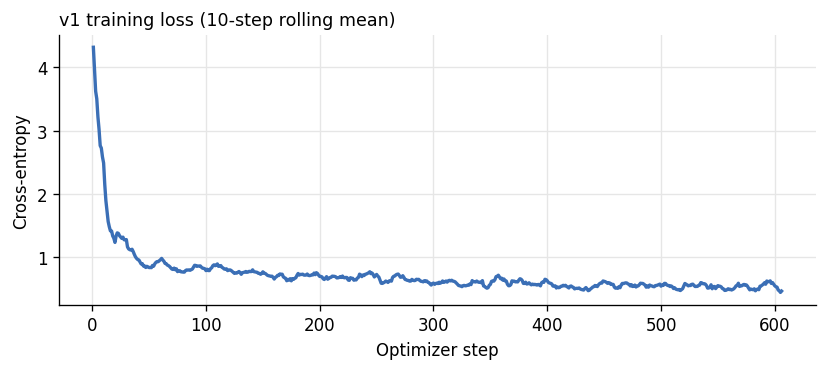

 step  agreement   ece    kl  letter_mass
  100      0.730 0.170 0.434        0.999
  200      0.744 0.131 0.372        0.998
  300      0.764 0.134 0.325        0.999
  400      0.784 0.134 0.319        1.000
  500      0.776 0.134 0.307        1.000
  600      0.784 0.138 0.308        1.000
  606      0.784 0.138 0.308        1.000


In [14]:
lg = pd.DataFrame(log)
fig, ax = plt.subplots(figsize=(7, 3.2), dpi=120)
ax.plot(lg["step"], lg["loss"].rolling(10, min_periods=1).mean(), color="#3b6fb6", lw=2)
ax.set_title("v1 training loss (10-step rolling mean)", fontsize=10.5, loc="left")
ax.set_xlabel("Optimizer step"); ax.set_ylabel("Cross-entropy")
ax.grid(color="#e6e6e6", lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(f"{SAVE_DIR}/loss_v1.png"); plt.show()
print(pd.DataFrame(val_log)[["step", "agreement", "ece", "kl", "letter_mass"]].round(3).to_string(index=False))

# Final exam: the same 2,000 rows as v0

In [15]:
eval_prompts = [build_prompt(r) for r in eval_s.to_dict("records")]
eval_ks = [len(o) for o in eval_s["options"]]
v1_dists, v1_mass = predict_distributions(model, eval_prompts, eval_ks)
v1_metrics, v1_bins = evaluate(v1_dists, eval_s["target"])
v1_metrics["letter_mass"] = float(v1_mass.mean())
v0_metrics["letter_mass"] = float(preds_v0["v0_letter_mass"].mean())

table = pd.DataFrame([{"version": "prior", **prior_metrics}, {"version": "v0", **v0_metrics}, {"version": "v1", **v1_metrics}])
print(table.round(3).to_string(index=False))
print("\nPer kind (v1):")
print(per_kind_table(v1_dists, eval_s).round(3).to_string(index=False))

version    n  agreement  expected_acc  mean_conf   ece    kl  brier  letter_mass
  prior 1998      0.399         0.387      0.415 0.028 0.493  0.255          NaN
     v0 1998      0.349         0.341      0.930 0.590 5.025  0.821        0.725
     v1 1998      0.788         0.629      0.776 0.148 0.319  0.126        1.000

Per kind (v1):
  kind   n  agreement  expected_acc  mean_conf   ece    kl  brier
choice 660      0.752         0.626      0.745 0.123 0.344  0.154
  noul 723      0.885         0.744      0.875 0.135 0.272  0.112
 score 615      0.712         0.498      0.692 0.195 0.347  0.114


In [16]:
print("Position-bias check: share of top picks per letter")
for kind, d in letter_picks(v1_dists, eval_s).items():
    print(f"{kind:>7} | v1 : {d['model']}\n{'':>7} | Jev: {d['jev']}")

Position-bias check: share of top picks per letter
 choice | v1 : {'A': 0.27, 'C': 0.26, 'B': 0.23, 'D': 0.22, 'E': 0.01, 'G': 0.0, 'F': 0.0, 'H': 0.0}
        | Jev: {'B': 0.27, 'A': 0.27, 'D': 0.23, 'C': 0.22, 'E': 0.01, 'G': 0.0, 'F': 0.0, 'H': 0.0}
   noul | v1 : {'A': 0.57, 'B': 0.43}
        | Jev: {'A': 0.55, 'B': 0.45}
  score | v1 : {'D': 0.52, 'E': 0.39, 'B': 0.04, 'F': 0.03, 'C': 0.01, 'A': 0.01}
        | Jev: {'D': 0.41, 'E': 0.36, 'C': 0.08, 'B': 0.07, 'F': 0.06, 'A': 0.02}


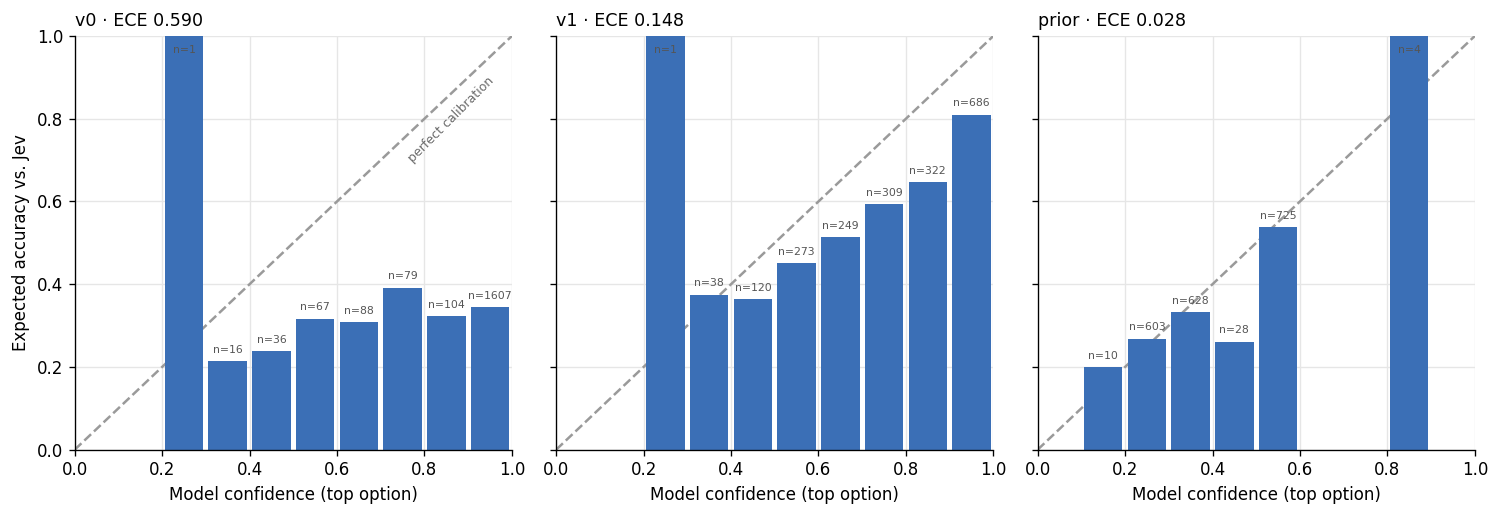

In [17]:
fig = reliability_panels([(f"v0 · ECE {v0_metrics['ece']:.3f}", v0_bins),
                          (f"v1 · ECE {v1_metrics['ece']:.3f}", v1_bins),
                          (f"prior · ECE {prior_metrics['ece']:.3f}", prior_bins)],
                         f"{SAVE_DIR}/reliability_v0_v1.png")
plt.show()

## Save
Appends `prior` and `v1` rows to `results.csv`, saves predictions and the final LoRA adapter (only ~tens of MB, since it's just the small matrices).

In [18]:
import datetime
now = datetime.datetime.now().isoformat(timespec="minutes")
res_path = f"{SAVE_DIR}/results.csv"
results = pd.read_csv(res_path) if os.path.exists(res_path) else pd.DataFrame()
new = pd.DataFrame([
    {"version": "prior", "model": "none", "method": "Jev average per (kind, k)", **prior_metrics, "run_at": now},
    {"version": "v1", "model": MODEL_ID, "method": f"QLoRA SFT hard labels, r={LORA_R}, lr={LR}, {len(train_rows)} rows",
     **v1_metrics, "run_at": now},
])
if "version" in results:
    results = results[~results["version"].isin(new["version"])]
results = pd.concat([results, new], ignore_index=True)
results.to_csv(res_path, index=False)

out = eval_s[["id", "kind", "domain", "target"]].copy()
out["v1_pred"] = [p.tolist() for p in v1_dists]
out["v1_letter_mass"] = v1_mass
out.to_parquet(f"{SAVE_DIR}/preds_v1.parquet")
model.save_pretrained(f"{SAVE_DIR}/v1_adapter")
print(results.round(3).to_string(index=False))

version           model                                             method    n  agreement  expected_acc  mean_conf   ece    kl  brier  letter_mass           run_at
     v0 Qwen/Qwen3-1.7B                                          zero-shot 1998      0.349         0.341      0.930 0.590 5.025  0.821        0.725 2026-10-13T16:58
  prior            none                          Jev average per (kind, k) 1998      0.399         0.387      0.415 0.028 0.493  0.255          NaN 2026-10-13T21:49
     v1 Qwen/Qwen3-1.7B QLoRA SFT hard labels, r=16, lr=0.0002, 19393 rows 1998      0.788         0.629      0.776 0.148 0.319  0.126        1.000 2026-10-13T21:49
